In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
import zipfile

DATA_DIR = "/content/drive/MyDrive/reid_project/VeRi.zip"

# Check if the zip file exists
if os.path.exists(DATA_DIR):
    print(f"File found: {DATA_DIR}. Unzipping...")

    # Define the extraction destination
    extract_to = "/content/VeRi"

    # Unzip the file
    with zipfile.ZipFile(DATA_DIR, 'r') as zip_ref:
        zip_ref.extractall(extract_to)

    print("Unzipping complete. Listing contents of target folder:")
    # Show the contents inside the unzipped folder
    for root, dirs, files in os.walk(extract_to):
        level = root.replace(extract_to, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        # List first 10 files to keep output clean
        for f in files[:10]:
            print(f"{subindent}{f}")
        if len(files) > 10:
            print(f"{subindent}... and {len(files) - 10} more files")
else:
    print(f"File not found at: {DATA_DIR}. Please check the path and try again.")

File found: /content/drive/MyDrive/reid_project/VeRi.zip. Unzipping...
Unzipping complete. Listing contents of target folder:
VeRi/
    VeRi/
        test_track_VeRi.txt
        YongtaiPoint_Google.jpg
        test_label.xml
        camera_Dist.txt
        ReadMe.txt
        jk_index.txt
        train_label.xml
        list_type.txt
        camera_ID.txt
        name_query.txt
        ... and 5 more files
        image_train/
            0112_c016_00011455_0.jpg
            0245_c019_00009070_0.jpg
            0765_c017_00041060_0.jpg
            0200_c009_00026985_0.jpg
            0453_c013_00008585_0.jpg
            0719_c012_00044515_0.jpg
            0500_c010_00016025_0.jpg
            0396_c010_00005445_0.jpg
            0665_c004_00057195_0.jpg
            0244_c017_00028735_0.jpg
            ... and 37768 more files
        image_query/
            0365_c003_00034590_0.jpg
            0489_c003_00084675_0.jpg
            0142_c016_00086325_0.jpg
            0298_c014_00045200_

In [4]:
!pip install -q timm

import os, math, random, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F, torchvision, timm
from torchvision import transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from collections import defaultdict

assert torch.cuda.is_available(), "Switch to a T4 GPU runtime first!"
device = "cuda"
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

R = "/content/VeRi/VeRi"                       # path from your unzip cell
CKPT_DIR = "/content/drive/MyDrive/reid_project/models"
os.makedirs(CKPT_DIR, exist_ok=True)

# ---------- parsing ----------
def parse(folder):
    fs = sorted(f for f in os.listdir(folder) if f.endswith(".jpg"))
    ids  = np.array([int(f.split("_")[0]) for f in fs])
    cams = np.array([int(f.split("_")[1][1:]) for f in fs])
    return np.array([os.path.join(folder, f) for f in fs]), ids, cams

q_paths, q_ids, q_cams = parse(f"{R}/image_query")
g_paths, g_ids, g_cams = parse(f"{R}/image_test")
tr_paths, tr_ids, tr_cams = parse(f"{R}/image_train")
print(len(q_paths), "queries |", len(g_paths), "gallery |", len(tr_paths), "train imgs")

# ---------- hold out 10% of train IDs for validation (query = 1 img/ID, gallery = rest) ----------
rng = random.Random(0)
all_ids = sorted(set(tr_ids))
val_ids = set(rng.sample(all_ids, max(1, len(all_ids) // 10)))
is_val = np.array([i in val_ids for i in tr_ids])

v_by_id = defaultdict(list)
for i in np.where(is_val)[0]:
    v_by_id[tr_ids[i]].append(i)
vq, vg = [], []
for k, idxs in v_by_id.items():
    if len(idxs) < 2: continue
    q = rng.choice(idxs); vq.append(q); vg += [i for i in idxs if i != q]
vq_paths, vq_ids, vq_cams = tr_paths[vq], tr_ids[vq], tr_cams[vq]
vg_paths, vg_ids, vg_cams = tr_paths[vg], tr_ids[vg], tr_cams[vg]

# ---------- training split ----------
trn_paths = list(tr_paths[~is_val]); trn_ids = tr_ids[~is_val]
uid = sorted(set(trn_ids)); id2lbl = {v: i for i, v in enumerate(uid)}
labels = np.array([id2lbl[i] for i in trn_ids])
by_id = defaultdict(list)
for i, l in enumerate(labels): by_id[l].append(i)
print(len(trn_paths), "train imgs,", len(uid), "train IDs |", len(vq_paths), "val q,", len(vg_paths), "val g")

# ---------- transforms (ResNet: 256x256, Swin: 224x224 so 56/28/14/7 divides window 7) ----------
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
def make_tfs(size):
    h, w = size
    train = T.Compose([T.Resize((h, w)), T.RandomHorizontalFlip(), T.Pad(10), T.RandomCrop((h, w)),
                       T.ColorJitter(0.2, 0.2, 0.1, 0.0),
                       T.ToTensor(), T.Normalize(MEAN, STD), T.RandomErasing(p=0.5)])
    test = T.Compose([T.Resize((h, w)), T.ToTensor(), T.Normalize(MEAN, STD)])
    return train, test

class ImgDS(Dataset):
    def __init__(self, paths, tf, labels=None): self.p, self.tf, self.y = paths, tf, labels
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        x = self.tf(Image.open(self.p[i]).convert("RGB"))
        return x if self.y is None else (x, int(self.y[i]))

class PKBatches(torch.utils.data.Sampler):
    """P identities x K images per batch (needed for batch-hard triplet)."""
    def __init__(self, P, K, iters):
        self.P, self.K, self.iters = P, K, iters
    def __len__(self): return self.iters
    def __iter__(self):
        ids = list(by_id.keys())
        for _ in range(self.iters):
            batch = []
            for l in random.sample(ids, self.P):
                pool = by_id[l]
                batch += random.choices(pool, k=self.K) if len(pool) < self.K else random.sample(pool, self.K)
            yield batch

# ---------- feature extraction (with optional flip TTA) + metrics ----------
@torch.no_grad()
def extract(model, paths, tf, bs=128, flip=True):
    model.eval().to(device)
    out = []
    for x in DataLoader(ImgDS(paths, tf), batch_size=bs, num_workers=2):
        x = x.to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            f = model(x).float()
            if flip: f = f + model(torch.flip(x, dims=[3])).float()
        out.append(F.normalize(f, dim=1).cpu())
    return torch.cat(out)

def reid_metrics(qf, qid, qcam, gf, gid, gcam):
    dist = (1 - qf @ gf.T).numpy()
    cmc = np.zeros(len(gid)); aps = []
    for i in range(len(qid)):
        order = np.argsort(dist[i])
        same = gid[order] == qid[i]
        junk = same & (gcam[order] == qcam[i])       # same ID + same camera -> ignored (VeRi protocol)
        hits = same[~junk]
        if hits.sum() == 0: continue
        first = np.where(hits)[0][0]
        cmc[first:] += 1
        prec = np.cumsum(hits) / (np.arange(len(hits)) + 1)
        aps.append(prec[hits].mean())
    n = len(aps)
    return dict(mAP=float(np.mean(aps)), rank1=cmc[0]/n, rank5=cmc[4]/n, rank10=cmc[9]/n)

def batch_hard_triplet(f, y, margin=0.3):
    f = F.normalize(f.float(), dim=1)
    d = torch.cdist(f, f)
    same = y[:, None] == y[None, :]
    d_pos = (d * same).max(1)[0]
    d_neg = (d + 1e6 * same).min(1)[0]
    return F.relu(d_pos - d_neg + margin).mean()

1678 queries | 11579 gallery | 37778 train imgs
34154 train imgs, 519 train IDs | 57 val q, 3567 val g


In [5]:
class ResNetMid(nn.Module):
    """Paper 1: concat GAP(mid-level layer3) + GAP(final layer4) -> BNNeck -> classifier."""
    def __init__(self, n_cls, last_stride=1):
        super().__init__()
        r = torchvision.models.resnet50(weights="IMAGENET1K_V2")
        if last_stride == 1:      # keeps layer4 at higher resolution (BoT trick, not from the paper)
            r.layer4[0].conv2.stride = (1, 1)
            r.layer4[0].downsample[0].stride = (1, 1)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu, r.maxpool, r.layer1, r.layer2)
        self.layer3, self.layer4 = r.layer3, r.layer4
        self.pool = nn.AdaptiveAvgPool2d(1)
        dim = 1024 + 2048
        self.bn = nn.BatchNorm1d(dim); self.bn.bias.requires_grad_(False)
        self.fc = nn.Linear(dim, n_cls, bias=False)
        nn.init.normal_(self.fc.weight, std=0.001)
    def forward(self, x):
        x = self.stem(x); mid = self.layer3(x); high = self.layer4(mid)
        f = torch.cat([self.pool(mid).flatten(1), self.pool(high).flatten(1)], 1)
        fb = self.bn(f)
        return (f, self.fc(fb)) if self.training else fb

class SwinReID(nn.Module):
    """Paper 1: Swin-S (C=96, depths 2,2,18,2), GAP over last stage -> BNNeck -> classifier."""
    def __init__(self, n_cls, name="swin_small_patch4_window7_224", drop_path=0.1):
        super().__init__()
        self.body = timm.create_model(name, pretrained=True, num_classes=0, drop_path_rate=drop_path)
        dim = self.body.num_features                      # 768
        self.bn = nn.BatchNorm1d(dim); self.bn.bias.requires_grad_(False)
        self.fc = nn.Linear(dim, n_cls, bias=False)
        nn.init.normal_(self.fc.weight, std=0.001)
    def forward(self, x):
        f = self.body(x)
        fb = self.bn(f)
        return (f, self.fc(fb)) if self.training else fb

# quick sanity check
m = SwinReID(len(uid)).to(device).eval()
with torch.no_grad(): print("Swin out:", m(torch.randn(2, 3, 224, 224, device=device)).shape)
del m; torch.cuda.empty_cache()

model.safetensors: reconstructing file:   0%|          |  0.00B /  200MB            

model.safetensors: downloading bytes:           |  0.00B            

Swin out: torch.Size([2, 768])


In [6]:
def train_model(model, name, size, P, K, epochs, lr, wd, head_lr_mult=10, iters=300,
                warmup=3, eval_every=2, patience=6, min_epochs=10, use_adamw=False):
    ckpt = f"{CKPT_DIR}/{name}.pt"
    train_tf, test_tf = make_tfs(size)
    loader = DataLoader(ImgDS(trn_paths, train_tf, labels), batch_sampler=PKBatches(P, K, iters),
                        num_workers=4, pin_memory=True)
    model.to(device)

    head = [p for n, p in model.named_parameters() if n.startswith(("bn.", "fc.")) and p.requires_grad]
    body = [p for n, p in model.named_parameters() if not n.startswith(("bn.", "fc.")) and p.requires_grad]
    groups = [dict(params=body, lr=lr), dict(params=head, lr=lr * head_lr_mult)]
    opt = (torch.optim.AdamW if use_adamw else torch.optim.Adam)(groups, weight_decay=wd)

    def lr_lambda(ep):
        if ep < warmup: return (ep + 1) / warmup
        p = (ep - warmup) / max(1, epochs - warmup)
        return max(0.01, 0.5 * (1 + math.cos(math.pi * p)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    scaler = torch.amp.GradScaler("cuda")
    ce = nn.CrossEntropyLoss(label_smoothing=0.1)

    best_map, bad, best_ep, t0 = -1.0, 0, 0, time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16):
                f, logits = model(x)
                loss = ce(logits, y) + batch_hard_triplet(f, y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item()
        sched.step()
        msg = f"[{name}] epoch {ep+1}/{epochs}  loss {tot/len(loader):.3f}  ({time.time()-t0:.0f}s)"

        if (ep + 1) % eval_every == 0:
            vqf = extract(model, vq_paths, test_tf, flip=False)
            vgf = extract(model, vg_paths, test_tf, flip=False)
            m = reid_metrics(vqf, vq_ids, vq_cams, vgf, vg_ids, vg_cams)
            msg += f"  val mAP {m['mAP']:.4f}  r1 {m['rank1']:.3f}"
            if m["mAP"] > best_map:
                best_map, best_ep, bad = m["mAP"], ep + 1, 0
                torch.save(model.state_dict(), ckpt); msg += "  *best*"
            else:
                bad += 1
            print(msg)
            if ep + 1 >= min_epochs and bad >= patience:
                print(f"Early stop @ {ep+1}. Best val mAP {best_map:.4f} @ epoch {best_ep}"); break
        else:
            print(msg)

    model.load_state_dict(torch.load(ckpt))
    return model, test_tf

In [7]:
RES_SIZE = (256, 256)
resmid = ResNetMid(len(uid), last_stride=1)
resmid, res_tf = train_model(resmid, "resnetmid_veri", RES_SIZE,
                             P=16, K=4, epochs=50, lr=3.5e-4, wd=5e-4, head_lr_mult=1)
qf = extract(resmid, q_paths, res_tf); gf = extract(resmid, g_paths, res_tf)
print("ResNetmid TEST:", {k: round(v, 4) for k, v in reid_metrics(qf, q_ids, q_cams, gf, g_ids, g_cams).items()})

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 90.0MB/s]
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:431: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:437: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rat

[resnetmid_veri] epoch 1/50  loss 5.105  (141s)
[resnetmid_veri] epoch 2/50  loss 2.699  (281s)  val mAP 0.6849  r1 0.842  *best*
[resnetmid_veri] epoch 3/50  loss 1.934  (431s)
[resnetmid_veri] epoch 4/50  loss 1.633  (565s)  val mAP 0.7123  r1 0.912  *best*
[resnetmid_veri] epoch 5/50  loss 1.502  (715s)
[resnetmid_veri] epoch 6/50  loss 1.439  (851s)  val mAP 0.7230  r1 0.895  *best*
[resnetmid_veri] epoch 7/50  loss 1.379  (1002s)
[resnetmid_veri] epoch 8/50  loss 1.360  (1136s)  val mAP 0.7148  r1 0.895
[resnetmid_veri] epoch 9/50  loss 1.330  (1284s)
[resnetmid_veri] epoch 10/50  loss 1.305  (1419s)  val mAP 0.7076  r1 0.895
[resnetmid_veri] epoch 11/50  loss 1.292  (1566s)
[resnetmid_veri] epoch 12/50  loss 1.272  (1700s)  val mAP 0.7121  r1 0.895
[resnetmid_veri] epoch 13/50  loss 1.261  (1849s)
[resnetmid_veri] epoch 14/50  loss 1.245  (1985s)  val mAP 0.7162  r1 0.877
[resnetmid_veri] epoch 15/50  loss 1.247  (2134s)
[resnetmid_veri] epoch 16/50  loss 1.232  (2276s)  val mAP 

In [12]:
# free GPU memory only if the ResNet model is still in memory
if "resmid" in globals():
    del resmid
torch.cuda.empty_cache()

SWIN_SIZE = (224, 224)
swin = SwinReID(len(uid))
swin, swin_tf = train_model(swin, "swins_veri", SWIN_SIZE,
                            P=12, K=4, epochs=20, lr=1e-4, wd=0.05, head_lr_mult=10,
                            use_adamw=True, patience=10, min_epochs=10)
qf = extract(swin, q_paths, swin_tf); gf = extract(swin, g_paths, swin_tf)
print("Swin-S TEST:", {k: round(v, 4) for k, v in reid_metrics(qf, q_ids, q_cams, gf, g_ids, g_cams).items()})

[swins_veri] epoch 1/20  loss 5.247  (159s)
[swins_veri] epoch 2/20  loss 3.023  (317s)  val mAP 0.7300  r1 0.895  *best*
[swins_veri] epoch 3/20  loss 2.125  (494s)
[swins_veri] epoch 4/20  loss 1.756  (653s)  val mAP 0.7719  r1 0.877  *best*
[swins_veri] epoch 5/20  loss 1.583  (830s)
[swins_veri] epoch 6/20  loss 1.478  (990s)  val mAP 0.8154  r1 0.912  *best*
[swins_veri] epoch 7/20  loss 1.393  (1170s)
[swins_veri] epoch 8/20  loss 1.353  (1328s)  val mAP 0.8234  r1 0.930  *best*
[swins_veri] epoch 9/20  loss 1.291  (1507s)
[swins_veri] epoch 10/20  loss 1.249  (1666s)  val mAP 0.8814  r1 0.965  *best*
[swins_veri] epoch 11/20  loss 1.217  (1845s)
[swins_veri] epoch 12/20  loss 1.176  (2005s)  val mAP 0.8661  r1 0.947
[swins_veri] epoch 13/20  loss 1.157  (2181s)
[swins_veri] epoch 14/20  loss 1.139  (2340s)  val mAP 0.8833  r1 0.965  *best*
[swins_veri] epoch 15/20  loss 1.117  (2519s)
[swins_veri] epoch 16/20  loss 1.106  (2678s)  val mAP 0.8737  r1 0.947
[swins_veri] epoch 17/2

In [13]:
# reload best checkpoints (n_cls = len(uid) is identical as long as Cell 1 ran in this session)
resmid = ResNetMid(len(uid), last_stride=1).to(device); resmid.load_state_dict(torch.load(f"{CKPT_DIR}/resnetmid_veri.pt"))
swin   = SwinReID(len(uid)).to(device);                 swin.load_state_dict(torch.load(f"{CKPT_DIR}/swins_veri.pt"))
_, res_tf  = make_tfs((256, 256));  _, swin_tf = make_tfs((224, 224))

def feats(paths_list):
    return ([extract(resmid, p, res_tf)  for p in paths_list],
            [extract(swin,   p, swin_tf) for p in paths_list])

(vq_r, vg_r), (vq_s, vg_s) = feats([vq_paths, vg_paths])
(q_r,  g_r),  (q_s,  g_s)  = feats([q_paths,  g_paths])

def fuse(fr, fs, w):   # concat with sqrt-weights -> still unit norm, cosine = w*sim_res + (1-w)*sim_swin
    return torch.cat([math.sqrt(w) * fr, math.sqrt(1 - w) * fs], dim=1)

print("Weight sweep on VALIDATION:")
best_w, best_m = 0.5, -1
for w in [0.0, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:
    m = reid_metrics(fuse(vq_r, vq_s, w), vq_ids, vq_cams, fuse(vg_r, vg_s, w), vg_ids, vg_cams)
    print(f"  w_resnet={w:.1f}  mAP {m['mAP']:.4f}  r1 {m['rank1']:.3f}")
    if m["mAP"] > best_m: best_m, best_w = m["mAP"], w
print("Chosen w_resnet:", best_w)

print("\n=== VeRi TEST ===")
for name, (qq, gg) in {"ResNetmid": (q_r, g_r), "Swin-S": (q_s, g_s),
                       "Fused 50/50": (fuse(q_r, q_s, .5), fuse(g_r, g_s, .5)),
                       f"Fused w={best_w}": (fuse(q_r, q_s, best_w), fuse(g_r, g_s, best_w))}.items():
    m = reid_metrics(qq, q_ids, q_cams, gg, g_ids, g_cams)
    print(f"{name:14s} mAP {m['mAP']:.4f} | r1 {m['rank1']:.4f} | r5 {m['rank5']:.4f} | r10 {m['rank10']:.4f}")

Weight sweep on VALIDATION:
  w_resnet=0.0  mAP 0.8820  r1 0.965
  w_resnet=0.2  mAP 0.8817  r1 0.930
  w_resnet=0.3  mAP 0.8755  r1 0.930
  w_resnet=0.4  mAP 0.8650  r1 0.912
  w_resnet=0.5  mAP 0.8565  r1 0.912
  w_resnet=0.6  mAP 0.8472  r1 0.912
  w_resnet=0.7  mAP 0.8288  r1 0.895
  w_resnet=0.8  mAP 0.8059  r1 0.895
  w_resnet=1.0  mAP 0.7407  r1 0.895
Chosen w_resnet: 0.0

=== VeRi TEST ===
ResNetmid      mAP 0.5509 | r1 0.8296 | r5 0.9041 | r10 0.9410
Swin-S         mAP 0.7381 | r1 0.9446 | r5 0.9750 | r10 0.9833
Fused 50/50    mAP 0.7051 | r1 0.9124 | r5 0.9613 | r10 0.9762
Fused w=0.0    mAP 0.7381 | r1 0.9446 | r5 0.9750 | r10 0.9833


In [14]:
!pip install -q ultralytics
import cv2, subprocess
from ultralytics import YOLO
from collections import defaultdict
import matplotlib.pyplot as plt

ROOT   = "/content/drive/MyDrive/reid_project"
YOLO_W = f"{ROOT}/models/weights/YOLOv11-S/UVH-26-MV-YOLOv11-S.pt"
W_RES  = best_w if "best_w" in globals() else 0.3     # fusion weight chosen on validation
OUT_DIR = f"{ROOT}/search_out"; os.makedirs(OUT_DIR, exist_ok=True)

open("/content/bytetrack_custom.yaml", "w").write("""tracker_type: bytetrack
track_high_thresh: 0.4
track_low_thresh: 0.1
new_track_thresh: 0.5
track_buffer: 60
match_thresh: 0.8
fuse_score: True
""")

res_tf  = make_tfs((256, 256))[1]
swin_tf = make_tfs((224, 224))[1]

@torch.no_grad()
def embed_pils(model, pils, tf, bs=64):
    model.eval().to(device); out = []
    for i in range(0, len(pils), bs):
        x = torch.stack([tf(p) for p in pils[i:i+bs]]).to(device)
        with torch.autocast("cuda", dtype=torch.float16):
            f = model(x).float() + model(torch.flip(x, dims=[3])).float()
        out.append(F.normalize(f, dim=1).cpu())
    return torch.cat(out)

def embed_fused(pils):
    return fuse(embed_pils(resmid, pils, res_tf), embed_pils(swin, pils, swin_tf), W_RES)

def load_query(path, detect=True):
    """Loads the query photo; if it's a whole scene, crops the largest detected vehicle."""
    bgr = cv2.imread(path); assert bgr is not None, f"Cannot read {path}"
    if detect:
        r = YOLO(YOLO_W)(bgr, conf=0.25, verbose=False)[0]
        if len(r.boxes):
            b = r.boxes.xyxy.cpu().numpy()
            x1, y1, x2, y2 = [int(v) for v in b[np.argmax((b[:,2]-b[:,0])*(b[:,3]-b[:,1]))]]
            bgr = bgr[max(y1,0):y2, max(x1,0):x2]
    pil = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB))
    plt.figure(figsize=(3,3)); plt.imshow(pil); plt.axis("off"); plt.title("Query crop"); plt.show()
    return pil

def analyze_video(video, top_k=8, min_span=15, min_side=32):
    """Detect + track + embed + score every track against the query. Cached for re-rendering."""
    model = YOLO(YOLO_W)
    cap = cv2.VideoCapture(video); assert cap.isOpened(), f"Cannot open {video}"
    per_frame = defaultdict(list)
    tracks = defaultdict(lambda: dict(first=None, last=None, crops=[]))
    fi = 0
    while True:
        ok, frame = cap.read()
        if not ok: break
        r = model.track(frame, persist=True, tracker="/content/bytetrack_custom.yaml",
                        conf=0.1, imgsz=640, verbose=False)[0]
        if r.boxes.id is not None:
            for b, tid, s in zip(r.boxes.xyxy.cpu().numpy(),
                                 r.boxes.id.cpu().numpy().astype(int),
                                 r.boxes.conf.cpu().numpy()):
                x1, y1, x2, y2 = [int(v) for v in b]; x1, y1 = max(x1,0), max(y1,0)
                t = tracks[tid]
                t["first"] = fi if t["first"] is None else t["first"]; t["last"] = fi
                per_frame[fi].append((tid, x1, y1, x2, y2))
                crop = frame[y1:y2, x1:x2]
                if min(crop.shape[:2]) >= min_side:
                    t["crops"].append(((x2-x1)*(y2-y1)*float(s), fi, crop.copy()))
                    t["crops"] = sorted(t["crops"], key=lambda c: -c[0])[:top_k]
        fi += 1
    fps = cap.get(cv2.CAP_PROP_FPS); W = int(cap.get(3)); H = int(cap.get(4)); cap.release()

    scores = {}
    for tid, t in tracks.items():
        if t["last"] - t["first"] + 1 < min_span or not t["crops"]: continue
        e = embed_fused([Image.fromarray(c[..., ::-1]) for _, _, c in t["crops"]])
        sims = (e @ q_emb.T).squeeze(1)
        scores[tid] = dict(score=float(sims.mean()), best=float(sims.max()),
                           first=t["first"], last=t["last"], crop=t["crops"][0][2])
    print(f"{os.path.basename(video)}: {fi} frames | {len(tracks)} raw tracks | {len(scores)} scored")
    return dict(video=video, per_frame=per_frame, scores=scores, fps=fps, size=(W, H), n=fi)

def show_ranking(info, n=6):
    top = sorted(info["scores"].items(), key=lambda kv: -kv[1]["score"])[:n]
    fig, axs = plt.subplots(1, len(top), figsize=(3*len(top), 3))
    axs = np.atleast_1d(axs)
    for ax, (tid, s) in zip(axs, top):
        ax.imshow(s["crop"][..., ::-1]); ax.axis("off")
        ax.set_title(f"track {tid}\nscore {s['score']:.2f}", fontsize=9)
    plt.show()

def render(info, thresh=0.6):
    """Draws green MATCH boxes on tracks scoring >= thresh, writes an mp4."""
    matched = {t for t, s in info["scores"].items() if s["score"] >= thresh}
    name = os.path.splitext(os.path.basename(info["video"]))[0]
    raw, final = f"/content/{name}_raw.mp4", f"{OUT_DIR}/{name}_found.mp4"
    wr = cv2.VideoWriter(raw, cv2.VideoWriter_fourcc(*"mp4v"), info["fps"], info["size"])
    cap = cv2.VideoCapture(info["video"])
    for i in range(info["n"]):
        ok, frame = cap.read()
        if not ok: break
        for tid, x1, y1, x2, y2 in info["per_frame"].get(i, []):
            if tid in matched:
                cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 3)
                cv2.putText(frame, f"MATCH {info['scores'][tid]['score']:.2f}", (x1, max(y1-8, 14)),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        wr.write(frame)
    cap.release(); wr.release()
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", raw, "-vf", "scale=1280:-2",
                    "-c:v", "libx264", "-pix_fmt", "yuv420p", "-crf", "23", final], check=True)
    print(f"{len(matched)} track(s) matched -> {final}")
    return final

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


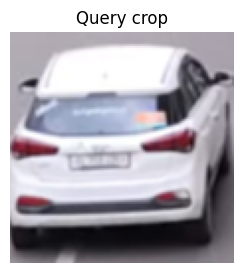

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 194ms
Prepared 1 package in 72ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 0.5s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

cam1.mp4: 805 frames | 48 raw tracks | 42 scored
cam2.mp4: 812 frames | 177 raw tracks | 73 scored

 /content/videos/cam1.mp4


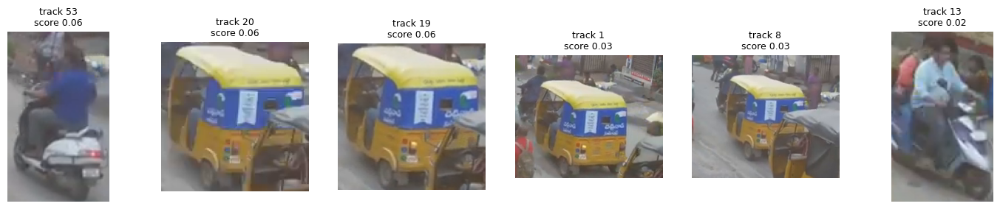


 /content/videos/cam2.mp4


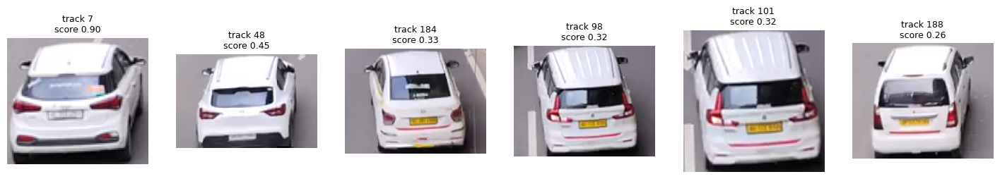

In [16]:
QUERY_IMG = "/content/my_car.png"                     # <- your photo
VIDEOS    = [f"/content/videos/cam1.mp4", f"/content/videos/cam2.mp4"]   # <- your videos

query = load_query(QUERY_IMG)
q_emb = embed_fused([query])                                # shape (1, D), unit norm

cache = {v: analyze_video(v) for v in VIDEOS}
for v in VIDEOS:
    print("\n", v); show_ranking(cache[v])

In [17]:
from IPython.display import Video
THRESH = 0.6          # adjust after looking at the scores above
finals = [render(cache[v], THRESH) for v in VIDEOS]
Video(finals[0], embed=True, width=800)

0 track(s) matched -> /content/drive/MyDrive/reid_project/search_out/cam1_found.mp4
1 track(s) matched -> /content/drive/MyDrive/reid_project/search_out/cam2_found.mp4


In [18]:
bundle = {
    "w_res":       float(best_w),                       # fusion weight chosen on validation
    "resnet":      {k: v.cpu() for k, v in resmid.state_dict().items() if not k.startswith("fc.")},
    "swin":        {k: v.cpu() for k, v in swin.state_dict().items()   if not k.startswith("fc.")},
    "res_size":    (256, 256),
    "swin_size":   (224, 224),
    "last_stride": 1,
    "swin_name":   "swin_small_patch4_window7_224",
    "mean": MEAN, "std": STD,
}
save_path = f"{CKPT_DIR}/fused_reid_veri.pt"
torch.save(bundle, save_path)
print("Saved:", save_path, f"| {os.path.getsize(save_path)/1e6:.0f} MB | w_res = {best_w}")

Saved: /content/drive/MyDrive/reid_project/models/fused_reid_veri.pt | 290 MB | w_res = 0.0
